## **Source Model Accuracy with Errors**

In [55]:
from pathlib import Path
from typing import Any, Literal

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt

from bloodmoon.io import simulation_files
from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count, decode, variance
from bloodmoon.optim import model_shadowgram, model_sky
import darksun as ds

from IROSrec.handle import config_dirpaths
import imgmaker as mgm

plt.rcdefaults()

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)

In [56]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
UPS_X, UPS_Y = 5, 1

SKYFIELD: str = "IROSDummy"
DATA_FITS: str = "baseline_2-50keV_1ks"

RUN_ID: str = 'Crab_rec_1ks_2-6keV_upx5'
E_min, E_max = 2.0, 6.0           # [keV]

hide_bulk_els_y: float = 1.5       # [mm] 

ID_CAMERA: str = 'cam1a'
# ID_CAMERA: str = 'cam1b'

In [57]:
from darksun.data import DataLoader, CatalogueLoader, Log

def extract_cam_data(
    camID: str,
    dl_path: str,
    cl_path: str,
    src_db_path: str,
    **dl_kws,
) -> tuple[DataLoader, CatalogueLoader, Log]:
    sdl_cam = ds.get_data(dl_path, **dl_kws)
    cat_cam = ds.get_catalogue(cl_path)
    _idx = 0 if camID[-1] == 'a' else 1
    log_cam = ds.load_database(src_db_path)[_idx]
    return sdl_cam, cat_cam, log_cam


MASK_PATH, SIMUL_DATA_PATH, SAVE_PATH = config_dirpaths(
    mask=MASK_FITS,
    skyfield=SKYFIELD,
    simul=DATA_FITS,
    runID=RUN_ID,
)
OUT_RESULTS_PATH = mgm.config_savedata_to()
wfm: CodedMaskCamera = codedmask(MASK_PATH, UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)
filepaths: dict[str, dict[str, Path]] = simulation_files(SIMUL_DATA_PATH)

sdl_cam, cat_cam, log_cam = extract_cam_data(
    camID=ID_CAMERA,
    dl_path=filepaths[ID_CAMERA]["reconstructed"],
    cl_path=filepaths[ID_CAMERA]["sources"],
    src_db_path=f"{SAVE_PATH}/IROS_sources_db.fits",
    E_min=E_min,
    E_max=E_max,
)

# Loading data...
# Loading completed!


CATALOG ='IROS_benchmark_catalogue_1ks.fits' / Catalog file                      [astropy.io.fits.card]


In [58]:
detector, _ = count(wfm, sdl_cam.DLdata)
varmap = variance(wfm, detector)
true_sky = decode(wfm, detector)

UserInfo: using bulk mask of [0.0 x 1.5] mm.


In [59]:
from bloodmoon.images import argmax

def find_boxmax(sky: NDArray, centre: tuple[int, int], boxsize: int = 5) -> tuple[int, int]:
    """Finds the argmax of given sky in a box centered around `pos`."""
    rcut, ccut = map(lambda idx: slice(idx - boxsize, idx + boxsize + 1), centre)
    p, q = centre
    n, m = argmax(sky[rcut, ccut])
    return p - boxsize + n, q - boxsize + m

def subtract_previous(
    camera: CodedMaskCamera,
    log: Log,
    up_to_src_idx: int,
    true_sky: NDArray,
    vignetting: bool = True,
    psfy: bool = True,
) -> NDArray:
    """Subtracts sources previous to IROS src index in `log`."""
    sky = true_sky.copy()
    for idx in range(up_to_src_idx):
        modelled = model_sky(
            camera, log.log['shift_x'][idx], log.log['shift_y'][idx],
            log.log['fluence'][idx], vignetting=vignetting, psfy=psfy
        )
        sky -= modelled
    return sky


IDX: int = 0
print(f'Analysing source {log_cam.log['ID'][IDX].upper()} from cam {ID_CAMERA.upper()}')

true_sky_ = subtract_previous(wfm, log_cam, IDX, true_sky) if IDX > 0 else true_sky
SRC_DATA = {
    'sx': log_cam.log['shift_x'][IDX],
    'sy': log_cam.log['shift_y'][IDX],
    'cts': log_cam.log['fluence'][IDX],
    'pos': find_boxmax(true_sky_, (log_cam.log['y'][IDX], log_cam.log['x'][IDX])),
    'crp': (35 * UPS_Y, 2 * (UPS_X - 1) + 1),
}

sg_model = model_shadowgram(wfm, SRC_DATA['sx'], SRC_DATA['sy']) * SRC_DATA['cts']
sky_model = decode(wfm, sg_model)
var_model = variance(wfm, sg_model)

get_cropped = lambda x: ds.crop(x, SRC_DATA['pos'], SRC_DATA['crp'])
psf_true, psf_var = map(get_cropped, (true_sky_, varmap))
psf_model, psf_model_var = map(get_cropped, (sky_model, var_model))

Analysing source S17 from cam CAM1A


In [60]:
def find_tick_val(ticks: NDArray, trg_vals: NDArray, atol: float = 1e-4) -> NDArray:
    """Finds the idxs inside `ticks` relative to given values `trg_vals`."""
    trg_idxs: list[int] = []
    for v in trg_vals:
        idx = np.argwhere(np.isclose(ticks, v, atol=atol))
        if idx.size > 0: trg_idxs.append(idx[0, 0])
    return np.array(trg_idxs)

def set_phase(x: NDArray) -> NDArray:
    """Centers `x` values around zero."""
    return np.arange(len(x) + 1) - len(x) // 2 - 0.5

def get_slices(*arrs: NDArray) -> tuple[tuple[NDArray, ...], tuple[NDArray, ...]]:
    n, m = arrs[0].shape
    xslice, yslice = zip(*tuple((c[(n - 1) // 2, :], c[:, (m - 1) // 2]) for c in arrs))
    return xslice, yslice

def get_heatmap_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
) -> tuple[NDArray, str]:
    """Handles source PSF residues heatmap to plot."""
    if mode == 'ratio':
        return psf / modelled, 'ratio'

    res = psf - modelled
    if mode == 'res':
        lbl = 'residues [ph]'
        if express_res_perc:
            res = res * 100 / psf.max()
            lbl = r'residues [%]'
        return res, lbl

    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))
    return res / sigma, 'residues [$\\sigma$]'

def get_slices_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
    n_sigma: int,
) -> tuple[NDArray, NDArray, str]:
    """
    Handles data to plot from source PSF and sigma slices, for both true and modelled.
    """
    if mode not in ('res', 'ratio', 'sigma'):
        raise ValueError(f"Invalid input mode '{mode}'.")
    
    if mode == 'ratio':
        sigma = psf_err / np.abs(modelled) + np.abs(psf / np.square(modelled)) * modelled_err
        return psf / modelled, n_sigma * sigma, 'ratio'

    res = psf - modelled
    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))

    if mode == 'res':
        lbl = 'residues [ph]'
        if express_res_perc:
            res, sigma = map(lambda x: x * 100 / psf.max(), (res, sigma))
            lbl = r'residues [%]'
        return res, n_sigma * sigma, lbl

    return res / sigma, n_sigma * np.ones_like(res), 'residues [$\\sigma$]'


def show_SPSF(
    camera: CodedMaskCamera,
    true_w_err: tuple[NDArray, NDArray],
    modelled_w_err: tuple[NDArray, NDArray],
    mode: Literal['res', 'ratio', 'sigma'],
    save_to: str | None = None,
    express_res_perc: bool = True,
    n_sigma: int = 1,
    cts_lims: tuple = (None, None),
    hm_res_lims: tuple = (None, None),
    fine_res_lims: tuple = (None, None),
    coarse_res_lims: tuple = (None, None),
    save_options: dict[str, Any] | None = None,
    **fig_kws,
) -> None:
    """
    Plots the SPSF heat maps and profiles along fine/coarse axes + cfr with modelled source.
    """
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)
    psf, modelled = true_w_err[0], modelled_w_err[0]
    psf_xslice, psf_yslice = get_slices(*true_w_err)
    modelled_xslice, modelled_yslice = get_slices(*modelled_w_err)

    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, mode, express_res_perc)

    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, mode, express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, mode, express_res_perc, n_sigma)

    slice_clrs = ('OrangeRed', 'DodgerBlue')
    errbar_factory = dict(
        linestyle='',
        elinewidth=0.7,
        capsize=0,
    )
    res_subtitle = 'Residues' if mode in ('res', 'sigma') else 'Ratio'

    # plot figure
    fig, axs = plt.subplots(2, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()
    
    # ------------------------ SPFS HEAT MAPS ------------------------
    img_layout = {'origin': 'lower', 'interpolation': 'none', 'aspect': 2 * psf.shape[1] / psf.shape[0]}
    vlim = max(np.abs(xres).max(), np.abs(yres).max())
    hm_res_lims_ = (
        hm_res_lims[0] or (-vlim + 1 if mode == 'ratio' else -vlim),
        hm_res_lims[1] or (vlim + 1 if mode == 'ratio' else vlim),
    )
    
    axs[0].set_title('Crab SPFS')
    psf_img = axs[0].imshow(psf, cmap='gist_heat', vmin=cts_lims[0], vmax=cts_lims[1], **img_layout)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('counts [ph]')
    axs[0].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[0].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    axs[3].set_title(f'Crab SPFS {res_subtitle}')
    mod_img = axs[3].imshow(psf_hm_res, vmin=hm_res_lims_[0], vmax=hm_res_lims_[1], **img_layout)
    cbar = fig.colorbar(mod_img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl)
    axs[3].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[3].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    yticks, xticks = map(lambda s: np.arange(0, s), psf.shape)
    _ytick_lbls, _xtick_lbls = (
        dty / 60 * (yticks - len(yticks) // 2), dtx * (xticks - len(xticks) // 2),
    )
    yticks_ = find_tick_val(_ytick_lbls, np.array([-5.0, -2.5, 0.0, 2.5, 5.0]), atol=7e-2)
    yticks_lbl = [float(f'{t:.1f}') for t in _ytick_lbls[yticks_]]
    xticks_ = find_tick_val(_xtick_lbls, np.array([-5.0, 0.0, 5.0]), atol=1e-1)
    xticks_lbl = [float(f'{t:.1f}') for t in _xtick_lbls[xticks_]]

    for idx in [0, 3]:
        axs[idx].set_xticks(xticks_, xticks_lbl)
        axs[idx].set_yticks(yticks_, yticks_lbl)

    # ------------------------ SPFS PROFILES | FINE AXIS ------------------------
    slice_lim_vals = max(modelled.max(), psf.max())
    y_lims = (cts_lims[0] or -0.075 * slice_lim_vals, cts_lims[1] or 1.05 * slice_lim_vals)

    x = dtx * set_phase(psf_xslice[0])
    xerr = dtx * (set_phase(psf_xslice[0])[:-1] + 0.5)

    xground = np.ones_like(x) if mode == 'ratio' else np.zeros_like(x)

    axs[1].set_title('SPFS Slice - Fine Axis')
    axs[1].stairs(psf_xslice[0], edges=x, edgecolor=slice_clrs[0], label='true')
    # axs[1].errorbar(xerr, psf_xslice[0], c=slice_clrs[0], yerr=psf_xslice[1], marker='', **errbar_factory)    # NOTE: too small
    axs[1].stairs(modelled_xslice[0], edges=x, edgecolor=slice_clrs[1], label='modelled')
    # axs[1].errorbar(xerr, modelled_xslice[0], c=slice_clrs[1], yerr=modelled_xslice[1], marker='', **errbar_factory)
    axs[1].set_ylim(y_lims)
    axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[1].yaxis.tick_right()

    axs[4].set_title(f'SPFS Slice {res_subtitle} - Fine Axis')
    axs[4].plot(x, xground, slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[4].stairs(xres, edges=x, edgecolor=slice_clrs[1], label=lbl)
    axs[4].errorbar(xerr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[4].set_ylim(fine_res_lims)
    axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[4].yaxis.tick_right()

    # ------------------------ SPFS PROFILES | COARSE AXIS ------------------------
    x = dty * set_phase(psf_yslice[0]) / 60
    xerr = dty * (set_phase(psf_yslice[0])[:-1] + 0.5) / 60

    xground = np.ones_like(x) if mode == 'ratio' else np.zeros_like(x)

    axs[2].set_title('SPFS Slice - Coarse Axis')
    axs[2].stairs(psf_yslice[0], edges=x, edgecolor=slice_clrs[0], label='true')
    # axs[2].errorbar(xerr, psf_yslice[0], c=slice_clrs[0], yerr=psf_yslice[1], marker='', **errbar_factory)    # NOTE: too small
    axs[2].stairs(modelled_yslice[0], edges=x, edgecolor=slice_clrs[1], label='modelled')
    # axs[2].errorbar(xerr, modelled_yslice[0], c=slice_clrs[1], yerr=modelled_yslice[1], marker='', **errbar_factory)
    axs[2].set_ylim(y_lims)
    axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[2].set_ylabel(ylabel='counts [ph]', labelpad=10)
    axs[2].yaxis.set_label_position('right')
    axs[2].yaxis.tick_right()

    axs[5].set_title(f'SPFS Slice {res_subtitle} - Coarse Axis')
    axs[5].plot(x, xground, slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[5].stairs(yres, edges=x, edgecolor=slice_clrs[1], label=lbl)
    axs[5].errorbar(xerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[5].set_ylim(coarse_res_lims)
    axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[5].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10)
    axs[5].yaxis.set_label_position('right')
    axs[5].yaxis.tick_right()

    for ax in axs:
        ax.xaxis.set_ticks_position('both')
        ax.yaxis.set_ticks_position('both')
        ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)
    for idx in [1, 2, 4, 5]:
        axs[idx].legend(loc='best')

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return

In [61]:
# PLOT_MODE: str = 'sigma'

# show_SPSF(
#     camera=wfm,
#     true_w_err=(psf_true, np.sqrt(psf_var)),
#     modelled_w_err=(psf_model, np.sqrt(psf_model_var)),
#     mode=PLOT_MODE,
#     express_res_perc=True,
#     n_sigma=1,
#     # save_to=f'{OUT_RESULTS_PATH}/CrabProfile/{ID_CAMERA}/Crab_wsigma_{PLOT_MODE}_1ks_{E_min}-{E_max}keV_{ID_CAMERA}.pdf',
#     figsize=(3.5 * 3 + 0.5, 3.5 * 2 + 0.5),
#     # fine_res_lims=(-12.0, 12.0),
#     # coarse_res_lims=(-12.0, 12.0),
# )

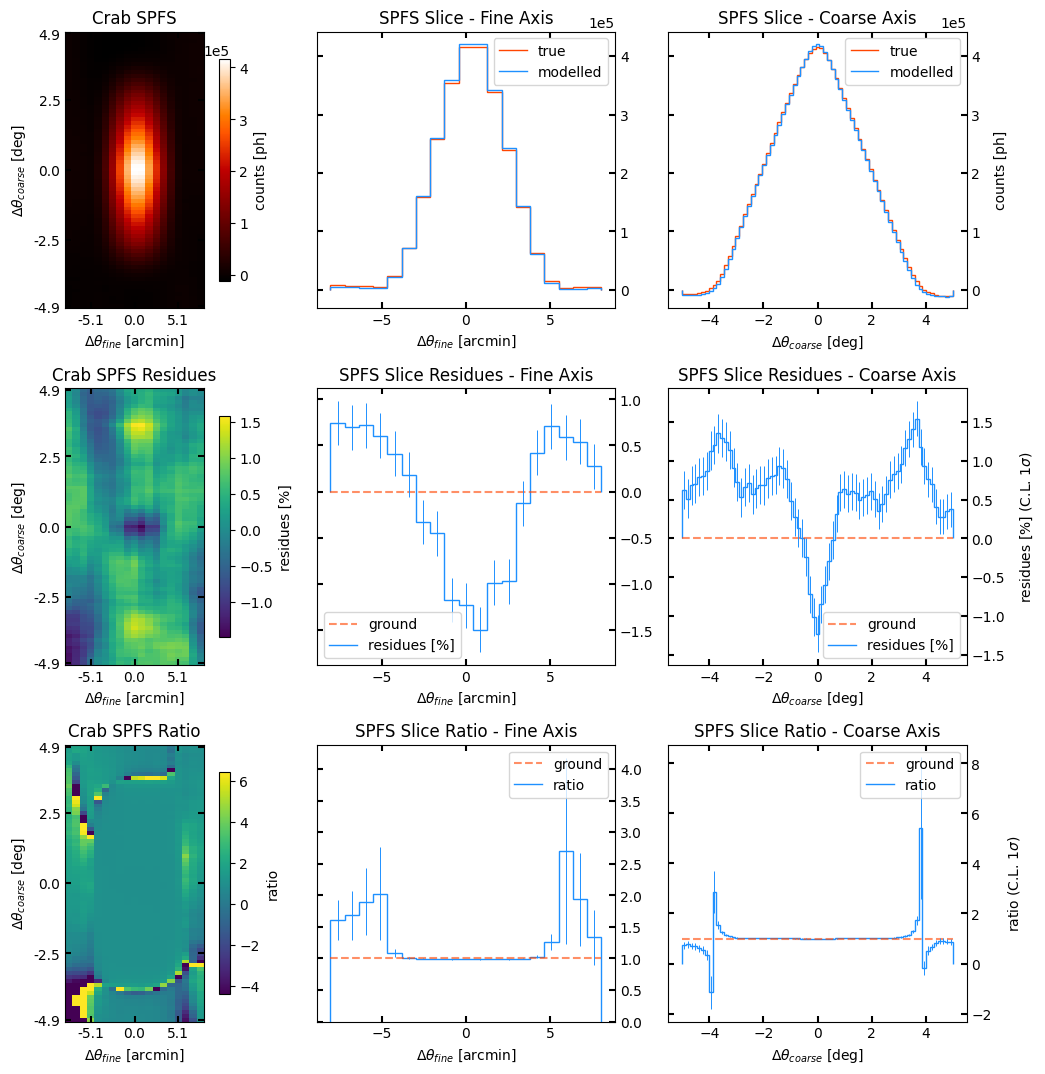

In [71]:
def show_SPSF_total(
    camera: CodedMaskCamera,
    true_w_err: tuple[NDArray, NDArray],
    modelled_w_err: tuple[NDArray, NDArray],
    save_to: str | None = None,
    express_res_perc: bool = True,
    n_sigma: int = 1,
    cts_lims: tuple = (None, None),
    hm_ratio_lims: tuple = (None, None),
    fine_ratio_lims: tuple = (None, None),
    coarse_ratio_lims: tuple = (None, None),
    save_options: dict[str, Any] | None = None,
    **fig_kws,
) -> None:
    """
    Plots the SPSF heat maps and profiles along fine/coarse axes + cfr with modelled source.
    """
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)
    psf, modelled = true_w_err[0], modelled_w_err[0]
    psf_xslice, psf_yslice = get_slices(*true_w_err)
    modelled_xslice, modelled_yslice = get_slices(*modelled_w_err)

    phase_fine, phase_coarse = (
        dtx * set_phase(psf_xslice[0]),
        dty * set_phase(psf_yslice[0]) / 60,
    )
    phase_ferr, phase_cerr = (
        dtx * (set_phase(psf_xslice[0])[:-1] + 0.5),
        dty * (set_phase(psf_yslice[0])[:-1] + 0.5) / 60,
    )
    
    slice_clrs = ('OrangeRed', 'DodgerBlue')
    img_factory = dict(origin='lower', interpolation='none', aspect=2 * psf.shape[1] / psf.shape[0])
    errbar_factory = dict(linestyle='', elinewidth=0.7, capsize=0)

    fig, axs = plt.subplots(3, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()

    # ------------------------ 1st ROW (SPSF HM + Profiles f/c) ---------------------------
    slice_lim_vals = max(modelled.max(), psf.max())
    slice_lim_vals = (cts_lims[0] or -0.075 * slice_lim_vals, cts_lims[1] or 1.05 * slice_lim_vals)
    
    axs[0].set_title('Crab SPFS')
    psf_img = axs[0].imshow(psf, cmap='gist_heat', vmin=cts_lims[0], vmax=cts_lims[1], **img_factory)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('counts [ph]')
    axs[0].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[0].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    axs[1].set_title('SPFS Slice - Fine Axis')
    axs[1].stairs(psf_xslice[0], edges=phase_fine, edgecolor=slice_clrs[0], label='true')
    axs[1].stairs(modelled_xslice[0], edges=phase_fine, edgecolor=slice_clrs[1], label='modelled')
    axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')

    axs[2].set_title('SPFS Slice - Coarse Axis')
    axs[2].stairs(psf_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[0], label='true')
    axs[2].stairs(modelled_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[1], label='modelled')
    axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[2].set_ylabel(ylabel='counts [ph]', labelpad=10)

    for idx in [1, 2]: axs[idx].set_ylim(slice_lim_vals)

    # ------------------------ 2nd ROW (RES [%] HM + Profiles f/c) ------------------------    
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, 'res', True)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, 'res', True, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, 'res', True, n_sigma)
    xres_sigma, _, lbl_sigma = get_slices_plot_data(*psf_xslice, *modelled_xslice, 'sigma', False, n_sigma)
    yres_sigma, _, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, 'sigma', False, n_sigma)

    axs[3].set_title(f'Crab SPFS Residues')
    mod_img = axs[3].imshow(psf_hm_res, **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl)
    axs[3].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[3].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    axs[4].set_title(f'SPFS Slice Residues - Fine Axis')
    axs[4].plot(phase_fine, np.zeros_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[4].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[4].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    # secax = axs[4].twinx()
    # secax.stairs(xres_sigma, edges=phase_fine, edgecolor='m')
    # secax.set_ylabel('residues [$\\sigma$]')
    # secax.yaxis.set_label_position('left')
    # secax.yaxis.set_ticks_position('left')
    # secax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)

    axs[5].set_title(f'SPFS Slice Residues - Coarse Axis')
    axs[5].plot(phase_coarse, np.zeros_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[5].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[5].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[5].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10)

    # ------------------------ 3rd ROW (RATIO HM + Profiles f/c) --------------------------
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, 'ratio', express_res_perc)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, 'ratio', express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, 'ratio', express_res_perc, n_sigma)

    vlim = max(np.abs(xres).max(), np.abs(yres).max())
    hm_res_lims_ = (hm_ratio_lims[0] or -vlim + 1, hm_ratio_lims[1] or vlim + 1)

    axs[6].set_title(f'Crab SPFS Ratio')
    mod_img = axs[6].imshow(psf_hm_res, vmin=hm_res_lims_[0], vmax=hm_res_lims_[1], **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[6], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl)
    axs[6].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[6].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    axs[7].set_title(f'SPFS Slice Ratio - Fine Axis')
    axs[7].plot(phase_fine, np.ones_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[7].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[7].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[7].set_ylim(fine_ratio_lims)
    axs[7].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')

    axs[8].set_title(f'SPFS Slice Ratio - Coarse Axis')
    axs[8].plot(phase_coarse, np.ones_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[8].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[8].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[8].set_ylim(coarse_ratio_lims)
    axs[8].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[8].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10)

    # ticks for HMs
    yticks, xticks = map(lambda s: np.arange(0, s), psf.shape)
    _ytick_lbls, _xtick_lbls = (
        dty / 60 * (yticks - len(yticks) // 2), dtx * (xticks - len(xticks) // 2),
    )
    yticks_ = find_tick_val(_ytick_lbls, np.array([-5.0, -2.5, 0.0, 2.5, 5.0]), atol=7e-2)
    yticks_lbl = [float(f'{t:.1f}') for t in _ytick_lbls[yticks_]]
    xticks_ = find_tick_val(_xtick_lbls, np.array([-5.0, 0.0, 5.0]), atol=1e-1)
    xticks_lbl = [float(f'{t:.1f}') for t in _xtick_lbls[xticks_]]

    for idx in [0, 3, 6]:
        axs[idx].set_xticks(xticks_, xticks_lbl)
        axs[idx].set_yticks(yticks_, yticks_lbl)
    
    for idx in [1, 2, 4, 5, 7, 8]:
        axs[idx].yaxis.tick_right()
        axs[idx].legend(loc='best')

    for idx in [2, 5, 8]:
        axs[idx].yaxis.set_label_position('right')

    for idx, ax in enumerate(axs):
        ax.xaxis.set_ticks_position('both')
        ax.yaxis.set_ticks_position('both')
        # ax.yaxis.set_ticks_position('right' if idx in (4, 5) else 'both')
        ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return




show_SPSF_total(
    camera=wfm,
    true_w_err=(psf_true, np.sqrt(psf_var)),
    modelled_w_err=(psf_model, np.sqrt(psf_model_var)),
    express_res_perc=True,
    n_sigma=1,
    # save_to=f'{OUT_RESULTS_PATH}/CrabProfile/{ID_CAMERA}/Crab_wsigma_GRID_1ks_{E_min}-{E_max}keV_{ID_CAMERA}.pdf',
    figsize=(3.5 * 3 + 0.5, 3.5 * 3 + 0.5),
    # fine_ratio_lims=(-12.0, 12.0),
    # coarse_ratio_lims=(-12.0, 12.0),
)

In [65]:
assert False

AssertionError: 

Data Variance


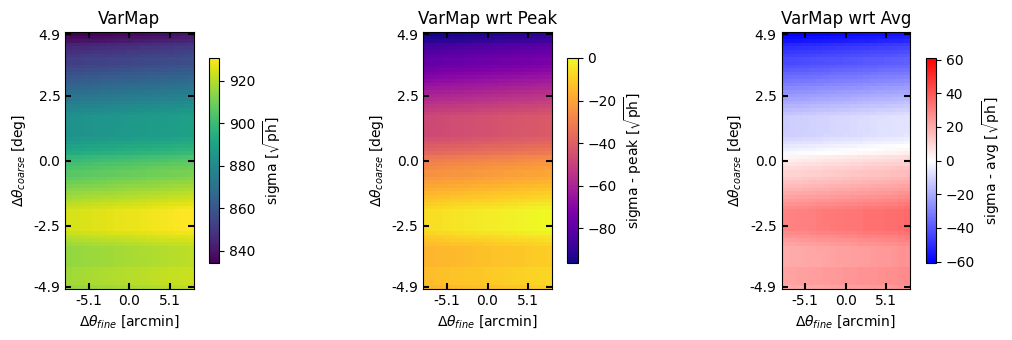

REPORT  =====================================
  * Std VS Peak: -35.421 +/- 27.414
  * Std VS Avg: -0.000 +/- 27.414



Source Model Variance


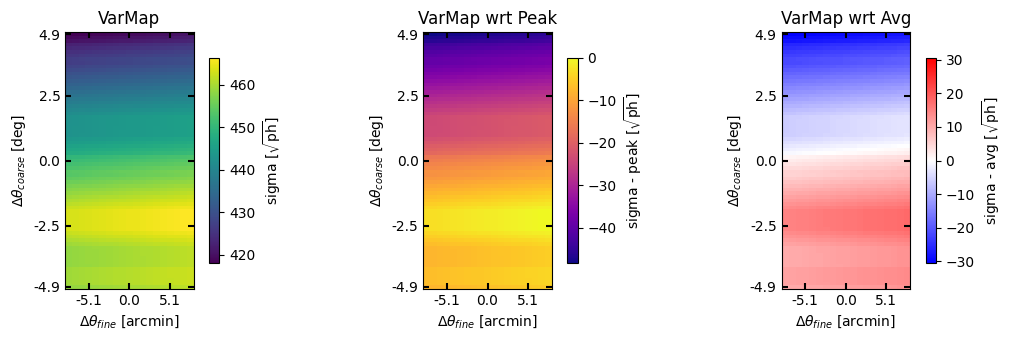

REPORT  =====================================
  * Std VS Peak: -17.746 +/- 13.735
  * Std VS Avg: -0.000 +/- 13.735



In [67]:
def inspect_srcvar(
    camera: CodedMaskCamera,
    varmap: NDArray,
    save_to: str | None = None,
    save_options: dict[str, Any] | None = None,
    **fig_kws,
) -> None:
    """
    Plots the source-cropped variance heat-map and deviations wrt peak and mean value.
    """
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)
    std = np.sqrt(varmap)

    n, m = varmap.shape
    img_layout = {'origin': 'lower', 'interpolation': 'none', 'aspect': 2 * m / n}
    peak, avg = std.max(), std.mean()

    fig, axs = plt.subplots(1, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()

    axs[0].set_title('VarMap')
    psf_img = axs[0].imshow(std, cmap='viridis', **img_layout)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('sigma [$\\sqrt{\\text{ph}}$]')

    std_vs_peak = std - peak
    axs[1].set_title('VarMap wrt Peak')
    psf_img = axs[1].imshow(std_vs_peak, cmap='plasma', **img_layout)
    cbar = fig.colorbar(psf_img, ax=axs[1], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('sigma - peak [$\\sqrt{\\text{ph}}$]')

    std_vs_avg = std - avg
    ylim = np.abs(std_vs_avg).max()
    axs[2].set_title('VarMap wrt Avg')
    psf_img = axs[2].imshow(std_vs_avg, cmap='bwr', vmin=-ylim, vmax=ylim, **img_layout)
    cbar = fig.colorbar(psf_img, ax=axs[2], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('sigma - avg [$\\sqrt{\\text{ph}}$]')


    yticks, xticks = map(lambda s: np.arange(0, s), varmap.shape)
    _ytick_lbls, _xtick_lbls = (
        dty / 60 * (yticks - len(yticks) // 2), dtx * (xticks - len(xticks) // 2),
    )
    yticks_ = find_tick_val(_ytick_lbls, np.array([-5.0, -2.5, 0.0, 2.5, 5.0]), atol=7e-2)
    yticks_lbl = [float(f'{t:.1f}') for t in _ytick_lbls[yticks_]]
    xticks_ = find_tick_val(_xtick_lbls, np.array([-5.0, 0.0, 5.0]), atol=1e-1)
    xticks_lbl = [float(f'{t:.1f}') for t in _xtick_lbls[xticks_]]

    for ax in axs:
        ax.set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
        ax.set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')
        ax.xaxis.set_ticks_position('both')
        ax.yaxis.set_ticks_position('both')
        ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)
        ax.set_xticks(xticks_, xticks_lbl)
        ax.set_yticks(yticks_, yticks_lbl)

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)

    plt.show()

    print(
        f"REPORT  {'=' * 37}\n"
        f"  * Std VS Peak: {std_vs_peak.mean():.3f} +/- {std_vs_peak.std():.3f}\n"
        f"  * Std VS Avg: {std_vs_avg.mean():.3f} +/- {std_vs_avg.std():.3f}\n"
        f"{'=' * 45}\n"
    )

    return



print("Data Variance")
inspect_srcvar(
    camera=wfm,
    varmap=psf_var,
    figsize=(3.5 * 3 + 0.5, 3.5),
)

print("\n\nSource Model Variance")
inspect_srcvar(
    camera=wfm,
    varmap=psf_model_var,
    figsize=(3.5 * 3 + 0.5, 3.5),
)

In [ ]:
def show_SPSF_secax(
    camera: CodedMaskCamera,
    true_w_err: tuple[NDArray, NDArray],
    modelled_w_err: tuple[NDArray, NDArray],
    mode: Literal['res', 'ratio', 'sigma'],
    save_to: str | None = None,
    express_res_perc: bool = True,
    n_sigma: int = 1,
    cts_lims: tuple = (None, None),
    hm_res_lims: tuple = (None, None),
    fine_res_lims: tuple = (None, None),
    coarse_res_lims: tuple = (None, None),
    save_options: dict[str, Any] | None = None,
    **fig_kws,
) -> None:
    """
    Plots the SPSF heat maps and profiles along fine/coarse axes + cfr with modelled source.
    """
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)

    if mode not in ('res', 'ratio', 'sigma'):
        raise ValueError(f"Invalid input mode '{mode}'.")
    
    psf, modelled = true_w_err[0], modelled_w_err[0]
    psf_xslice, psf_yslice = get_slices(*true_w_err)
    modelled_xslice, modelled_yslice = get_slices(*modelled_w_err)

    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, mode, express_res_perc)

    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, mode, express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, mode, express_res_perc, n_sigma)

    slice_clrs = ('OrangeRed', 'DodgerBlue')
    errbar_factory = dict(
        linestyle='',
        elinewidth=0.7,
        capsize=0,
    )
    res_subtitle = 'Residues' if mode in ('res', 'sigma') else 'Ratio'

    # plot figure
    fig, axs = plt.subplots(2, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()
    
    # ------------------------ SPFS HEAT MAPS ------------------------
    img_layout = {'origin': 'lower', 'interpolation': 'none', 'aspect': 2 * psf.shape[1] / psf.shape[0]}
    vlim = max(np.abs(xres).max(), np.abs(yres).max())
    hm_res_lims_ = (
        hm_res_lims[0] or (-vlim + 1 if mode == 'ratio' else -vlim),
        hm_res_lims[1] or (vlim + 1 if mode == 'ratio' else vlim),
    )
    
    axs[0].set_title('Crab SPFS')
    psf_img = axs[0].imshow(psf, cmap='gist_heat', vmin=cts_lims[0], vmax=cts_lims[1], **img_layout)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('counts [ph]')
    axs[0].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[0].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    axs[3].set_title(f'Crab SPFS {res_subtitle}')
    mod_img = axs[3].imshow(psf_hm_res, vmin=hm_res_lims_[0], vmax=hm_res_lims_[1], **img_layout)
    cbar = fig.colorbar(mod_img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl)
    axs[3].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[3].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]')

    yticks, xticks = map(lambda s: np.arange(0, s), psf.shape)
    _ytick_lbls, _xtick_lbls = (
        dty / 60 * (yticks - len(yticks) // 2), dtx * (xticks - len(xticks) // 2),
    )
    yticks_ = find_tick_val(_ytick_lbls, np.array([-5.0, -2.5, 0.0, 2.5, 5.0]), atol=7e-2)
    yticks_lbl = [float(f'{t:.1f}') for t in _ytick_lbls[yticks_]]
    xticks_ = find_tick_val(_xtick_lbls, np.array([-5.0, 0.0, 5.0]), atol=1e-1)
    xticks_lbl = [float(f'{t:.1f}') for t in _xtick_lbls[xticks_]]

    for idx in [0, 3]:
        axs[idx].set_xticks(xticks_, xticks_lbl)
        axs[idx].set_yticks(yticks_, yticks_lbl)

    # ------------------------ SPFS PROFILES | FINE AXIS ------------------------
    slice_lim_vals = max(modelled.max(), psf.max())
    y_lims = (cts_lims[0] or -0.075 * slice_lim_vals, cts_lims[1] or 1.05 * slice_lim_vals)

    x = dtx * set_phase(psf_xslice[0])
    xerr = dtx * (set_phase(psf_xslice[0])[:-1] + 0.5)

    xground = np.ones_like(x) if mode == 'ratio' else np.zeros_like(x)

    axs[1].set_title('SPFS Slice - Fine Axis')
    axs[1].stairs(psf_xslice[0], edges=x, edgecolor=slice_clrs[0], label='true')
    axs[1].stairs(modelled_xslice[0], edges=x, edgecolor=slice_clrs[1], label='modelled')
    axs[1].set_ylim(y_lims)
    axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[1].yaxis.tick_right()

    axs[4].set_title(f'SPFS Slice {res_subtitle} - Fine Axis')
    axs[4].plot(x, xground, slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[4].stairs(xres, edges=x, edgecolor=slice_clrs[1], label=lbl)
    axs[4].errorbar(xerr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)

    # fn = lambda x: x * xsigma
    # inv = lambda x_sec: x_sec / xsigma
    # secax = axs[4].secondary_yaxis('left', functions=(fn, inv))
    # secax.set_ylabel('residues [$\\sigma$]')
    # secax.yaxis.set_ticks_position('left')
    # secax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)

    secax = axs[4].twinx()
    secax.stairs(xres / xsigma, edges=x, edgecolor='m')
    secax.set_ylabel('residues [$\\sigma$]')
    secax.yaxis.set_ticks_position('left')
    secax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)

    # axs[4].set_ylim(fine_res_lims)
    axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]')
    axs[4].yaxis.tick_right()

    # ------------------------ SPFS PROFILES | COARSE AXIS ------------------------
    x = dty * set_phase(psf_yslice[0]) / 60
    xerr = dty * (set_phase(psf_yslice[0])[:-1] + 0.5) / 60

    xground = np.ones_like(x) if mode == 'ratio' else np.zeros_like(x)

    axs[2].set_title('SPFS Slice - Coarse Axis')
    axs[2].stairs(psf_yslice[0], edges=x, edgecolor=slice_clrs[0], label='true')
    axs[2].stairs(modelled_yslice[0], edges=x, edgecolor=slice_clrs[1], label='modelled')
    axs[2].set_ylim(y_lims)
    axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[2].set_ylabel(ylabel='counts [ph]', labelpad=10)
    axs[2].yaxis.set_label_position('right')
    axs[2].yaxis.tick_right()

    axs[5].set_title(f'SPFS Slice {res_subtitle} - Coarse Axis')
    axs[5].plot(x, xground, slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[5].stairs(yres, edges=x, edgecolor=slice_clrs[1], label=lbl)
    axs[5].errorbar(xerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)

    # scale = psf_yslice[0].max() / (100 * psf_yslice[1].max())
    # fn = lambda y: y * scale
    # inv = lambda y_sec: y_sec / scale
    # secax = axs[5].secondary_yaxis('left', functions=(fn, inv))
    # # secax.set_ylabel('residues [$\\sigma$]')
    # secax.yaxis.set_ticks_position('left')
    # secax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)

    # scale = psf_yslice[0].max() / (100 * psf_yslice[1])
    # secax = axs[5].twinx()
    # secax.stairs(yres * scale, edges=x, edgecolor=slice_clrs[1])
    # # secax.set_ylabel('residues [$\\sigma$]')
    # secax.yaxis.set_ticks_position('left')
    # secax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)
    
    # axs[5].set_ylim(coarse_res_lims)
    axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]')
    axs[5].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10)
    axs[5].yaxis.set_label_position('right')
    axs[5].yaxis.tick_right()

    for idx, ax in enumerate(axs):
        ax.xaxis.set_ticks_position('both')
        ax.yaxis.set_ticks_position('right' if idx in (4, 5) else 'both')
        ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5)
    for idx in [1, 2, 4, 5]:
        axs[idx].legend(loc='best')

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return

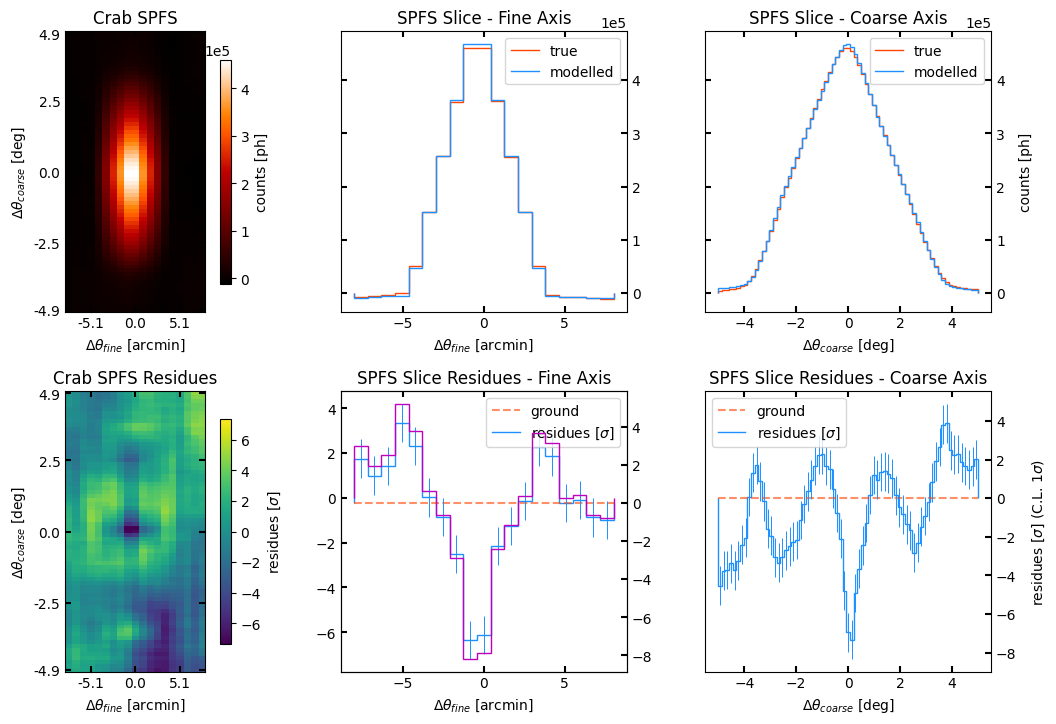

In [ ]:
# PLOT_MODE: str = 'sigma'

# show_SPSF_secax(
#     camera=wfm,
#     true_w_err=(psf_true, np.sqrt(psf_var)),
#     modelled_w_err=(psf_model, np.sqrt(psf_model_var)),
#     mode=PLOT_MODE,
#     express_res_perc=True,
#     n_sigma=1,
#     # save_to=f'{OUT_RESULTS_PATH}/CrabProfile/{ID_CAMERA}/Crab_wsigma_SECAX_1ks_{E_min}-{E_max}keV_{ID_CAMERA}.pdf',
#     figsize=(3.5 * 3 + 0.5, 3.5 * 2 + 0.5),
#     # fine_res_lims=(-12.0, 12.0),
#     # coarse_res_lims=(-12.0, 12.0),
# )